In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

ZIP_PATH = Path(
    "/content/drive/MyDrive/COMP3710/Final_Project_dataset/ADNI.zip"
)

WORK_DIR = Path("/content/comp3710_adni")
DATA_ROOT = WORK_DIR / "ADNI"

print("ZIP path:", ZIP_PATH)
print("ZIP exists:", ZIP_PATH.exists())

assert ZIP_PATH.exists(), (
    f"找不到数据压缩包：{ZIP_PATH}"
)

ZIP path: /content/drive/MyDrive/COMP3710/Final_Project_dataset/ADNI.zip
ZIP exists: True


In [3]:
import zipfile

IMAGE_ROOT = DATA_ROOT / "AD_NC"
METADATA_PATH = DATA_ROOT / "meta_data_with_label.json"

required_files_exist = (
    IMAGE_ROOT.exists()
    and METADATA_PATH.exists()
)

if not required_files_exist:
    WORK_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        ZIP_PATH,
        mode="r"
    ) as zip_file:

        # 忽略压缩包中的 macOS 辅助文件
        valid_members = [
            name
            for name in zip_file.namelist()
            if not name.startswith("__MACOSX/")
        ]

        zip_file.extractall(
            WORK_DIR,
            members=valid_members
        )

    print("Dataset extracted successfully.")
else:
    print("Dataset already extracted.")

Dataset extracted successfully.


In [4]:
print("Data root:", DATA_ROOT)
print("Image root:", IMAGE_ROOT)
print("Metadata:", METADATA_PATH)

print("Image root exists:", IMAGE_ROOT.exists())
print("Metadata exists:", METADATA_PATH.exists())

assert IMAGE_ROOT.exists()
assert METADATA_PATH.exists()

Data root: /content/comp3710_adni/ADNI
Image root: /content/comp3710_adni/ADNI/AD_NC
Metadata: /content/comp3710_adni/ADNI/meta_data_with_label.json
Image root exists: True
Metadata exists: True


In [5]:
for split in ["train", "test"]:

    for label in ["AD", "NC"]:

        folder = IMAGE_ROOT / split / label

        image_count = len(
            list(folder.glob("*.jpeg"))
        )

        print(
            f"{split}/{label}: "
            f"{image_count} images"
        )

train/AD: 10400 images
train/NC: 11120 images
test/AD: 4460 images
test/NC: 4540 images


In [7]:
import json
import re
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split


# ============================================================
# 1. 读取 metadata
# ============================================================

with open(METADATA_PATH, "r", encoding="utf-8") as file:
    metadata = json.load(file)

SUBJECT_PATTERN = re.compile(r"(\d{3}_S_\d{4})")
SCAN_PATTERN = re.compile(r"\b(I\d{3,})\b", re.IGNORECASE)


# ============================================================
# 2. 建立 scan ID -> subject ID 映射
# ============================================================

scan_to_subject = {}
conflicting_scans = set()

for scan_id, paths_dict in metadata.items():
    # 提取 scan_id 干净的数字或字母形式（比如去掉前后空格等，保持大写）
    clean_scan_id = scan_id.strip().upper()

    # 从路径中提取 subject_id
    subject_ids = set()
    for path_str in paths_dict.values():
        if isinstance(path_str, str):
            matches = SUBJECT_PATTERN.findall(path_str)
            for m in matches:
                subject_ids.add(m)

    if len(subject_ids) == 1:
        subject_id = next(iter(subject_ids))
        old_subject = scan_to_subject.get(clean_scan_id)
        if old_subject is not None and old_subject != subject_id:
            conflicting_scans.add(clean_scan_id)
        else:
            scan_to_subject[clean_scan_id] = subject_id
    elif len(subject_ids) > 1:
        # 如果同一个 Scan 对应了多个 Subject，记录下来
        conflicting_scans.add(clean_scan_id)

print("Metadata type:", type(metadata))
print("Scan-to-subject mappings:", len(scan_to_subject))
print("Conflicting scan IDs:", len(conflicting_scans))


# ============================================================
# 3. 扫描全部图片，建立 manifest
# ============================================================

image_paths = sorted(
    path
    for path in IMAGE_ROOT.rglob("*")
    if path.suffix.lower() in {".jpeg", ".jpg", ".png"}
)

rows = []
unmatched_files = []

for image_path in image_paths:
    # 图片文件名例如 1003730_100.jpeg, 其中 1003730 应该就是 scan_id 或包含 scan_id 的部分
    # 先尝试直接匹配文件名里的数字 (比如 1003730)
    # 考虑到可能文件名里是纯数字，我们把文件名中的非字母数字字符作为分隔符，或者直接提取前面的数字作为 scan_id 查找
    name_stem = image_path.stem
    scan_parts = re.split(r"_", name_stem)
    scan_id_candidate = scan_parts[0].upper() if scan_parts else ""

    # 如果直接匹配不到，尝试原先的 I_xxx 匹配
    scan_id = None
    if scan_id_candidate in scan_to_subject:
        scan_id = scan_id_candidate
    else:
        # 备份方案：带 I 的 scan_id
        scan_match = SCAN_PATTERN.search(image_path.name)
        if scan_match:
            backup_id = scan_match.group(1).upper()
            if backup_id in scan_to_subject:
                scan_id = backup_id

    if scan_id is None:
        # 如果还是找不到，尝试加上 "I" 前缀
        if f"I{scan_id_candidate}" in scan_to_subject:
            scan_id = f"I{scan_id_candidate}"

    if scan_id is None:
        unmatched_files.append(str(image_path))
        continue

    subject_id = scan_to_subject.get(scan_id)
    class_name = image_path.parent.name
    original_split = image_path.parent.parent.name

    if class_name not in {"AD", "NC"}:
        continue

    rows.append({
        "filepath": str(image_path),
        "label_name": class_name,
        "label": 1 if class_name == "AD" else 0,
        "scan_id": scan_id,
        "subject_id": subject_id,
        "original_split": original_split,
    })

manifest = pd.DataFrame(rows)

print("\nTotal image files:", len(image_paths))
print("Matched images:", len(manifest))
print("Unmatched images:", len(unmatched_files))

if unmatched_files:
    print("\nFirst unmatched files:")
    for filename in unmatched_files[:5]:
        print(filename)

assert len(manifest) == len(image_paths), (
    "部分图片无法与 metadata 匹配。"
    "请把本单元的输出发给我，不要继续训练。"
)


# ============================================================
# 4. 检查同一患者是否出现不同标签
# ============================================================

labels_per_subject = manifest.groupby("subject_id")["label"].nunique()
conflicting_subjects = labels_per_subject[labels_per_subject > 1]

assert conflicting_subjects.empty, (
    f"发现 {len(conflicting_subjects)} 个患者同时具有 AD 和 NC 标签。"
)


# ============================================================
# 5. 按患者进行 70% / 15% / 15% 划分
# ============================================================

subject_table = (
    manifest[["subject_id", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

train_subjects, temporary_subjects = train_test_split(
    subject_table,
    test_size=0.30,
    random_state=42,
    stratify=subject_table["label"],
)

validation_subjects, test_subjects = train_test_split(
    temporary_subjects,
    test_size=0.50,
    random_state=42,
    stratify=temporary_subjects["label"],
)

subject_to_split = {}

for subject_id in train_subjects["subject_id"]:
    subject_to_split[subject_id] = "train"

for subject_id in validation_subjects["subject_id"]:
    subject_to_split[subject_id] = "validation"

for subject_id in test_subjects["subject_id"]:
    subject_to_split[subject_id] = "test"

manifest["split"] = manifest["subject_id"].map(subject_to_split)


# ============================================================
# 6. 验证患者之间没有重叠
# ============================================================

train_ids = set(manifest.loc[manifest["split"] == "train", "subject_id"])
validation_ids = set(
    manifest.loc[manifest["split"] == "validation", "subject_id"]
)
test_ids = set(manifest.loc[manifest["split"] == "test", "subject_id"])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)


# ============================================================
# 7. 保存到 Google Drive
# ============================================================

MANIFEST_PATH = ZIP_PATH.parent / "patient_level_manifest.csv"
manifest.to_csv(MANIFEST_PATH, index=False)

print("\nImage counts:")
print(pd.crosstab(manifest["split"], manifest["label_name"]))

print("\nSubject counts:")
subject_summary = (
    manifest[["subject_id", "label_name", "split"]]
    .drop_duplicates()
)
print(pd.crosstab(subject_summary["split"], subject_summary["label_name"]))

print("\nTotal subjects:", manifest["subject_id"].nunique())
print("Manifest saved to:", MANIFEST_PATH)

manifest.head()

Metadata type: <class 'dict'>
Scan-to-subject mappings: 2189
Conflicting scan IDs: 0

Total image files: 30520
Matched images: 30520
Unmatched images: 0

Image counts:
label_name     AD     NC
split                   
test         2160   2340
train       10680  11020
validation   2020   2300

Subject counts:
label_name   AD   NC
split               
test         33   69
train       155  321
validation   33   69

Total subjects: 680
Manifest saved to: /content/drive/MyDrive/COMP3710/Final_Project_dataset/patient_level_manifest.csv


,filepath,label_name,label,scan_id,subject_id,original_split,split
0,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
1,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
2,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
3,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
4,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation


In [8]:
#读取并再次检查 manifest。这一阶段不会一次读取30,520张图片。DataLoader 只会按批次读取，例如每次读取64张
#（从Cell 1 到 Cell 6）
#Cell 1

from pathlib import Path

import pandas as pd
import torch

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/COMP3710/"
    "Final_Project_dataset/patient_level_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

# 清理可能由保存 DataFrame 索引产生的多余列
manifest = manifest.drop(
    columns=["index", "Unnamed: 0"],
    errors="ignore"
)

required_columns = {
    "filepath",
    "label_name",
    "label",
    "scan_id",
    "subject_id",
    "original_split",
    "split",
}

assert required_columns.issubset(manifest.columns)
assert len(manifest) == 30520
assert manifest["filepath"].is_unique
assert set(manifest["label"]) == {0, 1}
assert set(manifest["split"]) == {
    "train",
    "validation",
    "test",
}

# 检查图片路径
missing_files = [
    path
    for path in manifest["filepath"]
    if not Path(path).exists()
]

print("Manifest rows:", len(manifest))
print("Unique scans:", manifest["scan_id"].nunique())
print("Unique subjects:", manifest["subject_id"].nunique())
print("Missing files:", len(missing_files))

assert len(missing_files) == 0, (
    "找不到部分图片。Colab 重启后需要重新运行"
    "挂载 Drive 和解压数据的单元。"
)

manifest.head()

Manifest rows: 30520
Unique scans: 1526
Unique subjects: 680
Missing files: 0


,filepath,label_name,label,scan_id,subject_id,original_split,split
0,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
1,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
2,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
3,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation
4,/content/comp3710_adni/ADNI/AD_NC/test/AD/1003...,AD,1,1003730,135_S_6389,test,validation


In [9]:
#定义图像预处理
#ConvNeXt 的预训练权重接受三通道图片，而 MRI 是灰度图片。因此需要把一个灰度通道复制成三个通道。
#训练集进行轻微数据增强；验证集和测试集不使用随机增强。
#这里暂时不使用 ColorJitter，因为 MRI 不是普通彩色照片，过强的亮度或颜色变化可能改变医学图像的强度信息
#Cell 2

from torchvision import transforms


# ImageNet 预训练模型使用的归一化参数
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


train_transform = transforms.Compose([
    # 灰度图复制为三个通道
    transforms.Grayscale(num_output_channels=3),

    # 轻微裁剪和缩放
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.90, 1.00),
        ratio=(0.95, 1.05),
    ),

    # MRI 只进行小角度旋转
    transforms.RandomRotation(degrees=5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


evaluation_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(236),
    transforms.CenterCrop(224),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

In [10]:
#定义 ADNI Dataset
#Cell 3

from PIL import Image
from torch.utils.data import Dataset


class ADNISliceDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["filepath"]
        label = int(row["label"])
        subject_id = row["subject_id"]

        # 每次只读取当前需要的图片
        with Image.open(image_path) as image:
            image = image.convert("L")

            if self.transform is not None:
                image = self.transform(image)

        return image, label, subject_id

In [11]:
#创建训练、验证和测试 Dataset
#Cell 4

train_dataframe = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

validation_dataframe = manifest[
    manifest["split"] == "validation"
].reset_index(drop=True)

test_dataframe = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)


train_dataset = ADNISliceDataset(
    train_dataframe,
    transform=train_transform,
)

validation_dataset = ADNISliceDataset(
    validation_dataframe,
    transform=evaluation_transform,
)

test_dataset = ADNISliceDataset(
    test_dataframe,
    transform=evaluation_transform,
)


print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Testing images:", len(test_dataset))

Training images: 21700
Validation images: 4320
Testing images: 4500


In [12]:
# 创建 DataLoader
# A100 可以先使用 batch_size=64。如果以后出现显存不足，再改为32
#Cell 5

from torch.utils.data import DataLoader


SEED = 42
BATCH_SIZE = 64
NUM_WORKERS = 2

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)


print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))

Training batches: 340
Validation batches: 68
Testing batches: 71


Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
First labels: [1, 0, 0, 0, 1, 1, 1, 0, 0, 0]
First subject IDs: ['014_S_4615', '009_S_6286', '052_S_6412', '032_S_4277', '023_S_6661']


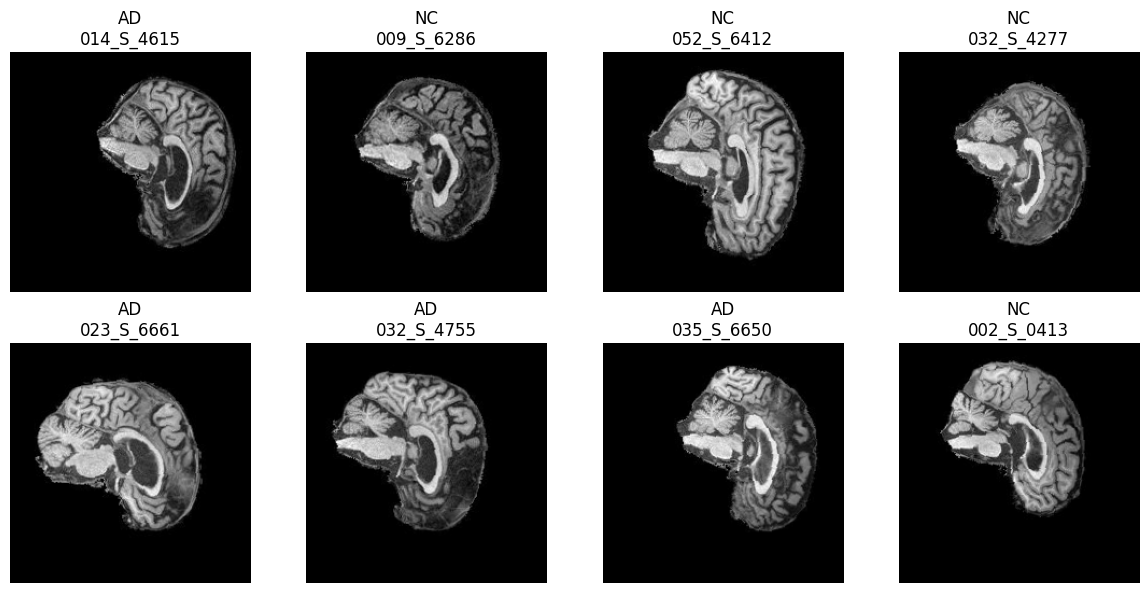

In [13]:
# 读取并显示一个批次
#Cell 6

import matplotlib.pyplot as plt


images, labels, subject_ids = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First labels:", labels[:10].tolist())
print("First subject IDs:", list(subject_ids[:5]))


mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

figure, axes = plt.subplots(2, 4, figsize=(12, 6))

for index, axis in enumerate(axes.flat):
    # 撤销归一化，用于显示
    display_image = images[index].cpu() * std + mean
    display_image = display_image.clamp(0, 1)

    axis.imshow(
        display_image[0],
        cmap="gray",
    )

    class_name = "AD" if labels[index].item() == 1 else "NC"

    axis.set_title(
        f"{class_name}\n{subject_ids[index]}"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# 先训练新分类层 2 轮，再解冻整个模型微调 6 轮。两阶段各自保存验证集表现最好的权重。
# ConvNeXt-Tiny 的模型接口和此前使用的 236 → 224 验证集预处理与 TorchVision 文档一致
#（From Cell 1 至 Cell 4）
# Cell 1：建立模型

import torch
import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

assert torch.cuda.is_available(), (
    "当前没有检测到 GPU。请在 Colab 的运行时设置中选择 A100 GPU。"
)

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# 固定本次训练的随机种子
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1
model = convnext_tiny(weights=weights)

# 原分类层输出 1000 个 ImageNet 类别；
# 改成两个类别：0=NC，1=AD
in_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(in_features, 2)

model = model.to(device)

# 检查一次前向传播
model.eval()
with torch.inference_mode():
    example_images, _, _ = next(iter(train_loader))
    example_logits = model(example_images[:2].to(device))

print("Model output shape:", tuple(example_logits.shape))
assert example_logits.shape == (2, 2)



GPU: NVIDIA A100-SXM4-40GB
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 235MB/s] 


Model output shape: (2, 2)


In [17]:
#定义训练与验证函数
#下面的验证准确率以图片为单位；最终报告还会计算以患者为单位的结果。目前不要使用测试集选模型
#cell 2

from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm

criterion = nn.CrossEntropyLoss()

OUTPUT_DIR = (
    Path("/content/drive/MyDrive/COMP3710/")
    / "Final_Project_dataset"
    / "convnext_results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

history = []


def run_one_epoch(loader, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    progress = tqdm(
        loader,
        desc="Train" if is_training else "Validation",
        leave=False,
    )

    for images, labels, _subject_ids in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            # A100 支持 bfloat16；这里用混合精度减少显存占用
            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_images += batch_size
        total_loss += loss.item() * batch_size
        total_correct += (
            (logits.argmax(dim=1) == labels).sum().item()
        )

    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }


def train_stage(stage_name, num_epochs, optimizer, checkpoint_path):
    best_validation_loss = float("inf")

    for epoch in range(1, num_epochs + 1):
        train_metrics = run_one_epoch(
            train_loader,
            optimizer=optimizer,
        )

        validation_metrics = run_one_epoch(
            validation_loader,
            optimizer=None,
        )

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "validation_loss": validation_metrics["loss"],
            "validation_accuracy": validation_metrics["accuracy"],
        }
        history.append(row)

        # 每轮写入 Drive，防止 Colab 中断后丢失训练记录
        pd.DataFrame(history).to_csv(
            OUTPUT_DIR / "training_history.csv",
            index=False,
        )

        improved = (
            validation_metrics["loss"] < best_validation_loss
        )

        if improved:
            best_validation_loss = validation_metrics["loss"]

            torch.save(
                {
                    "stage": stage_name,
                    "epoch": epoch,
                    "model_state": model.state_dict(),
                    "validation_loss": validation_metrics["loss"],
                    "validation_accuracy": (
                        validation_metrics["accuracy"]
                    ),
                    "class_to_index": {"NC": 0, "AD": 1},
                },
                checkpoint_path,
            )

        print(
            f"{stage_name} | epoch {epoch}/{num_epochs} | "
            f"train loss {train_metrics['loss']:.4f}, "
            f"acc {train_metrics['accuracy']:.4f} | "
            f"val loss {validation_metrics['loss']:.4f}, "
            f"acc {validation_metrics['accuracy']:.4f}"
            + (" | saved best" if improved else "")
        )

    print("Best checkpoint:", checkpoint_path)

In [18]:
#第一阶段，仅训练分类层
#Cell 3


# 冻结原来的卷积特征提取部分
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.classifier[-1].parameters():
    parameter.requires_grad = True

head_optimizer = torch.optim.AdamW(
    model.classifier[-1].parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

HEAD_CHECKPOINT = OUTPUT_DIR / "convnext_head_best.pt"

train_stage(
    stage_name="classifier_head",
    num_epochs=2,
    optimizer=head_optimizer,
    checkpoint_path=HEAD_CHECKPOINT,
)

Train:   0%|          | 0/340 [00:00<?, ?it/s]

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

classifier_head | epoch 1/2 | train loss 0.5120, acc 0.7564 | val loss 0.4743, acc 0.7676 | saved best


Train:   0%|          | 0/340 [00:00<?, ?it/s]

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

classifier_head | epoch 2/2 | train loss 0.5008, acc 0.7660 | val loss 0.4641, acc 0.7731 | saved best
Best checkpoint: /content/drive/MyDrive/COMP3710/Final_Project_dataset/convnext_results/convnext_head_best.pt


In [19]:
# 第二阶段，微调整个模型
# 第一阶段完成后再运行此单元。它会先载入第一阶段的最佳权重，然后解冻模型。
# 特征提取部分使用较小学习率，新的分类层使用较大学习率。
# Cell 4


head_checkpoint = torch.load(
    HEAD_CHECKPOINT,
    map_location=device,
    weights_only=True,
)
model.load_state_dict(head_checkpoint["model_state"])

for parameter in model.parameters():
    parameter.requires_grad = True

finetune_optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features.parameters(),
            "lr": 1e-5,
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4,
        },
    ],
    weight_decay=1e-4,
)

FINETUNE_CHECKPOINT = OUTPUT_DIR / "convnext_finetune_best.pt"

train_stage(
    stage_name="full_finetune",
    num_epochs=6,
    optimizer=finetune_optimizer,
    checkpoint_path=FINETUNE_CHECKPOINT,
)

Train:   0%|          | 0/340 [00:00<?, ?it/s]

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

full_finetune | epoch 1/6 | train loss 0.4015, acc 0.8214 | val loss 0.3894, acc 0.8116 | saved best


Train:   0%|          | 0/340 [00:00<?, ?it/s]

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

full_finetune | epoch 5/6 | train loss 0.1185, acc 0.9559 | val loss 0.6000, acc 0.7759


Train:   0%|          | 0/340 [00:00<?, ?it/s]

Validation:   0%|          | 0/68 [00:00<?, ?it/s]

full_finetune | epoch 6/6 | train loss 0.0966, acc 0.9636 | val loss 0.5363, acc 0.8039
Best checkpoint: /content/drive/MyDrive/COMP3710/Final_Project_dataset/convnext_results/convnext_finetune_best.pt


In [20]:
# 下一步先核对保存的最佳模型，再做一次正式测试
# 下面的评估会分别给出图片级和患者级准确率；患者级预测先平均同一扫描的切片概率，再平均同一患者的扫描概率
#（From Cell 1 to Cell 3）


#Cell 1：加载预先选定的最佳模型
head_info = torch.load(
    HEAD_CHECKPOINT,
    map_location="cpu",
    weights_only=True,
)
finetune_info = torch.load(
    FINETUNE_CHECKPOINT,
    map_location="cpu",
    weights_only=True,
)

print(
    "Head checkpoint:",
    head_info["stage"],
    head_info["epoch"],
    head_info["validation_loss"],
)
print(
    "Finetune checkpoint:",
    finetune_info["stage"],
    finetune_info["epoch"],
    finetune_info["validation_loss"],
)

# 使用此前确定的“验证损失最低”规则
selected_path = min(
    [HEAD_CHECKPOINT, FINETUNE_CHECKPOINT],
    key=lambda path: torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )["validation_loss"],
)

selected_info = torch.load(
    selected_path,
    map_location=device,
    weights_only=True,
)

model.load_state_dict(selected_info["model_state"])
model.eval()

print("Selected:", selected_path.name)
print("Stage:", selected_info["stage"])
print("Epoch:", selected_info["epoch"])
print("Saved validation loss:", selected_info["validation_loss"])

Head checkpoint: classifier_head 2 0.46406637474342627
Finetune checkpoint: full_finetune 1 0.3893914187396014
Selected: convnext_finetune_best.pt
Stage: full_finetune
Epoch: 1
Saved validation loss: 0.3893914187396014


In [21]:
# Cell 2：定义评估函数
# 这里 0=NC，1=AD，预测 AD 的固定阈值为 0.5。ROC-AUC 使用 AD 的预测概率，混淆矩阵的行是真实类别、列是预测类别


from torch.utils.data import SequentialSampler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score,
)


def collect_predictions(loader):
    assert isinstance(loader.sampler, SequentialSampler), (
        "评估 DataLoader 必须设置 shuffle=False，"
        "才能将预测与 manifest 行正确对应。"
    )

    rows = loader.dataset.dataframe[
        ["filepath", "label", "scan_id", "subject_id", "split"]
    ].reset_index(drop=True).copy()

    probabilities = []
    observed_labels = []
    observed_subjects = []

    model.eval()

    with torch.inference_mode():
        for images, labels, subject_ids in loader:
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16,
            ):
                logits = model(images)

            prob_ad = torch.softmax(
                logits.float(),
                dim=1,
            )[:, 1]

            probabilities.extend(prob_ad.cpu().tolist())
            observed_labels.extend(labels.tolist())
            observed_subjects.extend(list(subject_ids))

    assert len(probabilities) == len(rows)
    assert observed_labels == rows["label"].astype(int).tolist()
    assert observed_subjects == rows["subject_id"].tolist()

    rows["prob_ad"] = probabilities
    rows["pred_label"] = (
        rows["prob_ad"] >= 0.5
    ).astype(int)

    return rows


def aggregate_predictions(image_rows):
    # 同一扫描中的切片属于同一个标签
    assert (
        image_rows.groupby(
            ["subject_id", "scan_id"]
        )["label"].nunique() == 1
    ).all()

    scan_rows = (
        image_rows.groupby(
            ["subject_id", "scan_id"],
            as_index=False,
        )
        .agg(
            label=("label", "first"),
            prob_ad=("prob_ad", "mean"),
        )
    )

    # 同一患者的扫描属于同一个标签
    assert (
        scan_rows.groupby("subject_id")["label"].nunique() == 1
    ).all()

    patient_rows = (
        scan_rows.groupby(
            "subject_id",
            as_index=False,
        )
        .agg(
            label=("label", "first"),
            prob_ad=("prob_ad", "mean"),
        )
    )

    for table in [scan_rows, patient_rows]:
        table["pred_label"] = (
            table["prob_ad"] >= 0.5
        ).astype(int)

    return scan_rows, patient_rows


def calculate_metrics(rows):
    truth = rows["label"].astype(int)
    prediction = rows["pred_label"].astype(int)

    metrics = {
        "samples": len(rows),
        "accuracy": accuracy_score(truth, prediction),
        "balanced_accuracy": balanced_accuracy_score(
            truth,
            prediction,
        ),
        "ad_recall": recall_score(
            truth,
            prediction,
            pos_label=1,
            zero_division=0,
        ),
        "ad_f1": f1_score(
            truth,
            prediction,
            pos_label=1,
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            truth,
            rows["prob_ad"],
        ),
    }

    matrix = confusion_matrix(
        truth,
        prediction,
        labels=[0, 1],
    )

    return metrics, matrix


def evaluate_split(loader, split_name):
    image_rows = collect_predictions(loader)

    assert set(image_rows["split"]) == {split_name}

    scan_rows, patient_rows = aggregate_predictions(
        image_rows
    )

    result_rows = []

    for level, rows in [
        ("image", image_rows),
        ("scan", scan_rows),
        ("patient", patient_rows),
    ]:
        metrics, matrix = calculate_metrics(rows)

        result_rows.append({
            "split": split_name,
            "level": level,
            **metrics,
        })

        print(f"\n{split_name} — {level}")
        print(
            "Confusion matrix "
            "(rows=actual, columns=predicted; NC, AD):"
        )
        print(matrix)

        rows.to_csv(
            OUTPUT_DIR / f"{split_name}_{level}_predictions.csv",
            index=False,
        )

    summary = pd.DataFrame(result_rows)
    print(f"\n{split_name} metrics:")
    display(summary.round(4))

    summary.to_csv(
        OUTPUT_DIR / f"{split_name}_metrics.csv",
        index=False,
    )

    return summary

In [22]:
# Cell 3：先核对验证集，再评估测试集


validation_summary = evaluate_split(
    validation_loader,
    "validation",
)

test_summary = evaluate_split(
    test_loader,
    "test",
)


validation — image
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[1849  451]
 [ 363 1657]]

validation — scan
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[101  14]
 [ 18  83]]

validation — patient
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[62  7]
 [ 7 26]]

validation metrics:


,split,level,samples,accuracy,balanced_accuracy,ad_recall,ad_f1,roc_auc
0,validation,image,4320,0.8116,0.8121,0.8203,0.8028,0.9065
1,validation,scan,216,0.8519,0.8500,0.8218,0.8384,0.9372
2,validation,patient,102,0.8627,0.8432,0.7879,0.7879,0.9183



test — image
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[1856  484]
 [ 175 1985]]

test — scan
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[ 99  18]
 [  4 104]]

test — patient
Confusion matrix (rows=actual, columns=predicted; NC, AD):
[[59 10]
 [ 1 32]]

test metrics:


,split,level,samples,accuracy,balanced_accuracy,ad_recall,ad_f1,roc_auc
0,test,image,4500,0.8536,0.8561,0.9190,0.8576,0.9384
1,test,scan,225,0.9022,0.9046,0.9630,0.9043,0.9661
2,test,patient,102,0.8922,0.9124,0.9697,0.8533,0.9565


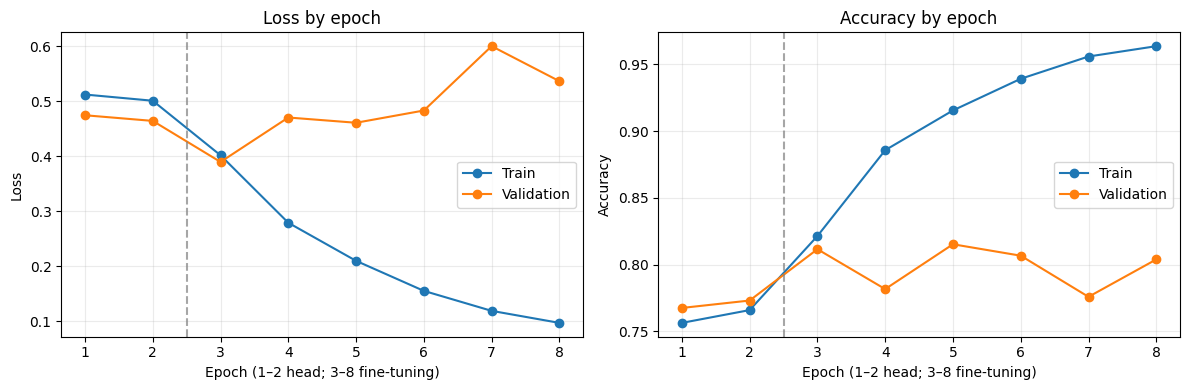

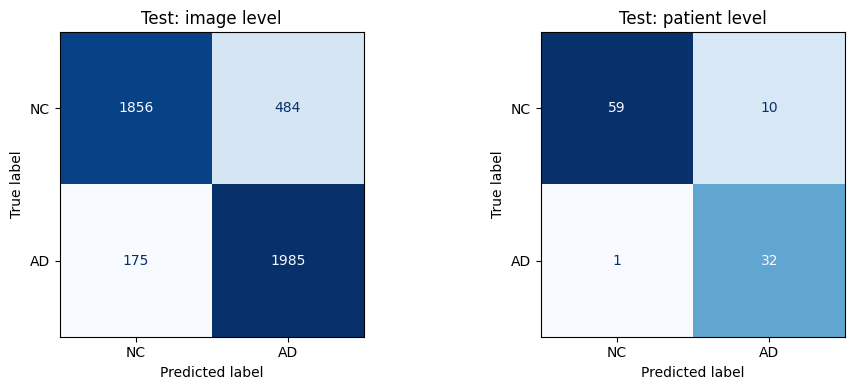

Figures saved to: /content/drive/MyDrive/COMP3710/Final_Project_dataset/convnext_results


In [23]:
# 保存报告用图。从已经保存的 CSV 生成训练曲线和测试集混淆矩阵


import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

history_df = pd.read_csv(
    OUTPUT_DIR / "training_history.csv"
)

epochs = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    history_df["train_loss"],
    marker="o",
    label="Train",
)
axes[0].plot(
    epochs,
    history_df["validation_loss"],
    marker="o",
    label="Validation",
)
axes[0].set(
    title="Loss by epoch",
    xlabel="Epoch (1–2 head; 3–8 fine-tuning)",
    ylabel="Loss",
)
axes[0].legend()

axes[1].plot(
    epochs,
    history_df["train_accuracy"],
    marker="o",
    label="Train",
)
axes[1].plot(
    epochs,
    history_df["validation_accuracy"],
    marker="o",
    label="Validation",
)
axes[1].set(
    title="Accuracy by epoch",
    xlabel="Epoch (1–2 head; 3–8 fine-tuning)",
    ylabel="Accuracy",
)
axes[1].legend()

for axis in axes:
    axis.axvline(2.5, color="gray", linestyle="--", alpha=0.7)
    axis.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for axis, level in zip(axes, ["image", "patient"]):
    predictions = pd.read_csv(
        OUTPUT_DIR / f"test_{level}_predictions.csv"
    )

    matrix = confusion_matrix(
        predictions["label"],
        predictions["pred_label"],
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["NC", "AD"],
    ).plot(
        ax=axis,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    axis.set_title(f"Test: {level} level")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Figures saved to:", OUTPUT_DIR)